In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA
df = pd.read_csv("winequality-red.csv")

In [4]:
df

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5
1,7.8,0.880,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,5
2,7.8,0.760,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,5
3,11.2,0.280,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,6
4,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5
...,...,...,...,...,...,...,...,...,...,...,...,...
1594,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5
1595,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6
1596,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6
1597,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5


In [5]:
print(df.shape)
print(df.columns)
print(df.isnull().sum())

(1599, 12)
Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='str')
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64


In [6]:
x = df.drop("quality", axis=1)
y = df["quality"]

normalizer = MinMaxScaler()
x_normalized = normalizer.fit_transform(x)

In [7]:
x_normalized

array([[0.24778761, 0.39726027, 0.        , ..., 0.60629921, 0.13772455,
        0.15384615],
       [0.28318584, 0.52054795, 0.        , ..., 0.36220472, 0.20958084,
        0.21538462],
       [0.28318584, 0.43835616, 0.04      , ..., 0.40944882, 0.19161677,
        0.21538462],
       ...,
       [0.15044248, 0.26712329, 0.13      , ..., 0.53543307, 0.25149701,
        0.4       ],
       [0.11504425, 0.35958904, 0.12      , ..., 0.65354331, 0.22754491,
        0.27692308],
       [0.12389381, 0.13013699, 0.47      , ..., 0.51181102, 0.19760479,
        0.4       ]], shape=(1599, 11))

In [8]:
print(pd.DataFrame(x_normalized, columns=x.columns))

      fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0          0.247788          0.397260         0.00        0.068493   0.106845   
1          0.283186          0.520548         0.00        0.116438   0.143573   
2          0.283186          0.438356         0.04        0.095890   0.133556   
3          0.584071          0.109589         0.56        0.068493   0.105175   
4          0.247788          0.397260         0.00        0.068493   0.106845   
...             ...               ...          ...             ...        ...   
1594       0.141593          0.328767         0.08        0.075342   0.130217   
1595       0.115044          0.294521         0.10        0.089041   0.083472   
1596       0.150442          0.267123         0.13        0.095890   0.106845   
1597       0.115044          0.359589         0.12        0.075342   0.105175   
1598       0.123894          0.130137         0.47        0.184932   0.091820   

      free sulfur dioxide  

In [9]:
standardizer = StandardScaler()
x_standard = standardizer.fit_transform(x)
pd.DataFrame(x_standard, columns=x.columns).head().round(3)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,-0.528,0.962,-1.391,-0.453,-0.244,-0.466,-0.379,0.558,1.289,-0.579,-0.960
1,-0.299,1.967,-1.391,0.043,0.224,0.873,0.624,0.028,-0.720,0.129,-0.585
2,-0.299,1.297,-1.186,-0.169,0.096,-0.084,0.229,0.134,-0.331,-0.048,-0.585
3,1.655,-1.384,1.484,-0.453,-0.265,0.108,0.412,0.664,-0.979,-0.461,-0.585
4,-0.528,0.962,-1.391,-0.453,-0.244,-0.466,-0.379,0.558,1.289,-0.579,-0.960


In [10]:
pca = PCA(n_components=2)
x_pca = pca.fit_transform(x_standard)

pd.DataFrame(x_pca, columns=["PC1", "PC2"]).head().round(2)

,PC1,PC2
0,-1.62,0.45
1,-0.80,1.86
2,-0.75,0.88
3,2.36,-0.27
4,-1.62,0.45


In [11]:
print(x.shape, x_pca.shape)

(1599, 11) (1599, 2)


In [15]:
pca.explained_variance_ratio_.round(4)
print(round(sum(pca.explained_variance_ratio_) * 100, 2), "%")

45.68 %


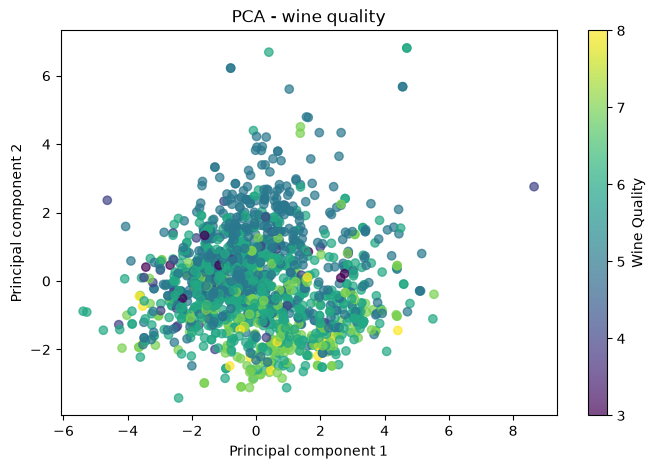

In [13]:
plt.figure(figsize=(8,5))
plt.scatter(x_pca[:,0], x_pca[:,1], c=y,cmap="viridis", alpha=0.7)
plt.xlabel("Principal component 1")
plt.ylabel("Principal component 2")
plt.title("PCA - wine quality")
plt.colorbar(label="Wine Quality")
plt.show()